# 04 · Churn Prediction (Model 1: classification)
**Task:** using only information available on **2025-09-30**, predict which customers will cancel in the following 9 months (`churned_next`).

Required by the PRD: train/test split, categorical encoding, class-imbalance handling, cross-validation, Accuracy / Precision / Recall / F1 / ROC-AUC / confusion matrix, written model-choice justification with the precision/recall trade-off in a retention-offer context.

**Expect modest scores.** The PRD says the churn relationship is intentionally noisy, and notebook 03 showed that a *leaky* build reaches AUC 0.71 while the honest one reaches about 0.60. Everything here is the honest version.

In [1]:
import sys; sys.path.insert(0, '..')
import json, joblib, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

PROC = Path('../data/processed'); FIG = Path('../reports/figures'); MODELS = Path('../models'); REP = Path('../reports')
for p in (FIG, MODELS, REP): p.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); RED, GREY, BLUE, GREEN = '#E50914', '#8C8C8C', '#2B6CB0', '#2F855A'
SEED = 42

## 1 · Data, feature lists and train/test split

In [2]:
df = pd.read_csv(PROC / 'features_snapshot.csv', parse_dates=['as_of', 'registration_date'])
y = df.churned_next.values
CAT = ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'plan_name', 'last_payment_method']
DROP = ['customer_id', 'as_of', 'registration_date', 'churned_next']
NUM = [c for c in df.columns if c not in CAT + DROP]
X = df[NUM + CAT]
print(f'{len(df):,} customers | {len(NUM)} numeric + {len(CAT)} categorical features | positive rate {y.mean():.2%}')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print(f'train {len(X_train):,} (pos {y_train.mean():.2%}) | test {len(X_test):,} (pos {y_test.mean():.2%})')

7,273 customers | 31 numeric + 7 categorical features | positive rate 24.41%
train 5,818 (pos 24.41%) | test 1,455 (pos 24.40%)


## 2 · Preprocessing and class imbalance
* Numeric: median imputation (CSAT / feedback features are blank for customers with no ticket / feedback; `has_csat` already flags that). Scaled for the linear model.
* Categorical: one-hot, rare levels (<20 customers) grouped, unseen levels ignored at scoring time.
* **Imbalance (24% churners):** handled with class weights (`balanced` / `scale_pos_weight`) instead of resampling, so the test set keeps its real class mix and the probabilities stay usable.

In [3]:
def preprocessor(scale):
    num = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    return ColumnTransformer([('num', Pipeline(num), NUM),
                              ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False), CAT)])

spw = (y_train == 0).sum() / (y_train == 1).sum()
candidates = {
 'Logistic Regression': (Pipeline([('pre', preprocessor(True)), ('m', LogisticRegression(class_weight='balanced', max_iter=3000))]),
                         {'m__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1]}),
 'Random Forest': (Pipeline([('pre', preprocessor(False)), ('m', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
                   {'m__max_depth': [4, 6, 8, 12], 'm__min_samples_leaf': [10, 20, 40, 80], 'm__max_features': ['sqrt', 0.3]}),
 'Gradient Boosting': (Pipeline([('pre', preprocessor(False)), ('m', HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED))]),
                       {'m__max_depth': [2, 3, 4], 'm__learning_rate': [0.02, 0.05, 0.1], 'm__max_iter': [100, 200, 300], 'm__min_samples_leaf': [20, 50, 100], 'm__l2_regularization': [0, 1, 10]}),
 'XGBoost': (Pipeline([('pre', preprocessor(False)), ('m', XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', n_jobs=-1, random_state=SEED, tree_method='hist'))]),
             {'m__max_depth': [2, 3, 4], 'm__learning_rate': [0.02, 0.05, 0.1], 'm__n_estimators': [100, 200, 400], 'm__subsample': [0.7, 0.9],
              'm__colsample_bytree': [0.5, 0.8], 'm__min_child_weight': [5, 20, 50]}),
}
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

## 3 · Baseline comparison: 5-fold cross-validation on the training set (default settings)

In [4]:
rows = []
for name, (pipe, _) in candidates.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring={'auc': 'roc_auc', 'ap': 'average_precision'}, n_jobs=1)
    rows.append({'model': name, 'cv_auc_mean': r['test_auc'].mean(), 'cv_auc_std': r['test_auc'].std(), 'cv_pr_auc': r['test_ap'].mean()})
base = pd.DataFrame(rows).set_index('model').round(4); print(f'Reference: random guessing ROC-AUC = 0.500, PR-AUC = {y_train.mean():.3f}'); base

Reference: random guessing ROC-AUC = 0.500, PR-AUC = 0.244


,cv_auc_mean,cv_auc_std,cv_pr_auc
model,,,
Logistic Regression,0.5860,0.0139,0.3111
Random Forest,0.5626,0.0083,0.2881
Gradient Boosting,0.5439,0.0133,0.2770
XGBoost,0.5215,0.0101,0.2654


## 4 · Hyper-parameter tuning (randomised search, 3-fold CV on the training set, optimise ROC-AUC)

In [5]:
tuned, rows = {}, []
for name, (pipe, grid) in candidates.items():
    s = RandomizedSearchCV(pipe, grid, n_iter=12, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='roc_auc', random_state=SEED, n_jobs=1, refit=True)
    s.fit(X_train, y_train); tuned[name] = s.best_estimator_
    rows.append({'model': name, 'tuned_cv_auc': s.best_score_, 'best_params': {k.replace('m__', ''): v for k, v in s.best_params_.items()}})
tuning = pd.DataFrame(rows).set_index('model'); tuning['tuned_cv_auc'] = tuning.tuned_cv_auc.round(4)
pd.set_option('display.max_colwidth', 200); tuning

,tuned_cv_auc,best_params
model,,
Logistic Regression,0.6001,{'C': 0.003}
Random Forest,0.5949,"{'min_samples_leaf': 80, 'max_features': 0.3, 'max_depth': 6}"
Gradient Boosting,0.5885,"{'min_samples_leaf': 20, 'max_iter': 100, 'max_depth': 3, 'learning_rate': 0.02, 'l2_regularization': 0}"
XGBoost,0.5930,"{'subsample': 0.9, 'n_estimators': 200, 'min_child_weight': 20, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.5}"


## 5 · Held-out test results (threshold 0.50)
Test set = 20% of customers never used for fitting or tuning.

In [6]:
def metrics_at(y_true, proba, thr=.5):
    pred = (proba >= thr).astype(int)
    return {'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0), 'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred), 'roc_auc': roc_auc_score(y_true, proba), 'pr_auc': average_precision_score(y_true, proba)}
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in tuned.items()}
res = pd.DataFrame({n: metrics_at(y_test, p) for n, p in probs.items()}).T.round(3)
res['tuned_cv_auc'] = tuning.tuned_cv_auc
res

,accuracy,precision,recall,f1,roc_auc,pr_auc,tuned_cv_auc
Logistic Regression,0.594,0.310,0.541,0.394,0.621,0.336,0.6001
Random Forest,0.601,0.299,0.473,0.366,0.601,0.337,0.5949
Gradient Boosting,0.592,0.306,0.532,0.389,0.606,0.333,0.5885
XGBoost,0.603,0.313,0.527,0.393,0.616,0.347,0.5930


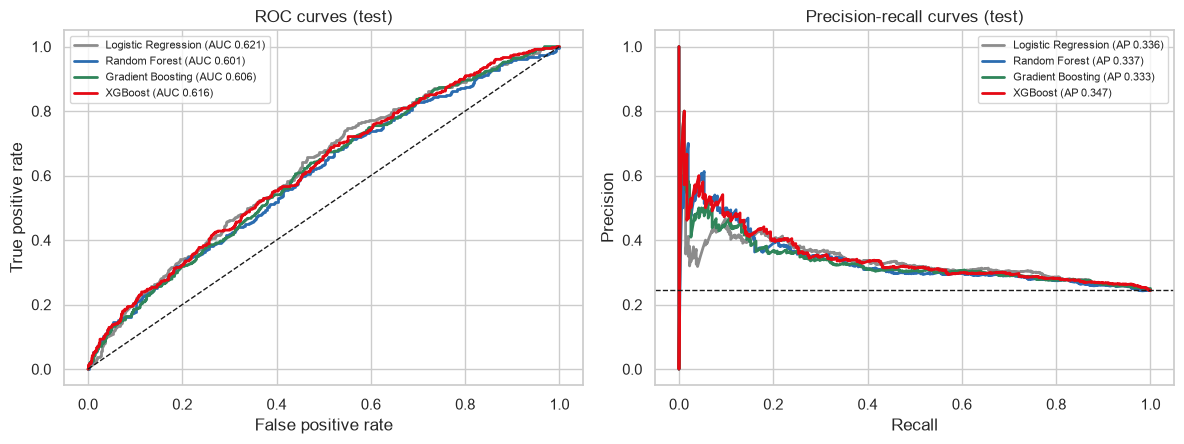

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6)); cols = [GREY, BLUE, GREEN, RED]
for (n, p), c in zip(probs.items(), cols):
    f, t, _ = roc_curve(y_test, p); axes[0].plot(f, t, color=c, lw=2, label=f'{n} (AUC {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, color=c, lw=2, label=f'{n} (AP {average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].set_title('ROC curves (test)'); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-recall curves (test)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '34_churn_roc_pr.png', dpi=130, bbox_inches='tight'); plt.show()

## 6 · Choosing the final model
Selection rule, decided *before* looking at the test set: highest **tuned cross-validated ROC-AUC**. If another model is within one standard error of the best, prefer the simpler / more interpretable one. The test set is only used to confirm.

In [8]:
cv_auc = tuning.tuned_cv_auc; best = cv_auc.idxmax()
se = base.loc[best, 'cv_auc_std'] / np.sqrt(5)
simpler_order = ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']        # simplest -> most complex
close = [m for m in simpler_order if cv_auc[m] >= cv_auc[best] - se]
FINAL = close[0]
print(f'Best tuned CV AUC: {best} ({cv_auc[best]:.4f}); 1 SE = {se:.4f}; models within 1 SE: {close}')
print('FINAL MODEL ->', FINAL)
final_model, p_final = tuned[FINAL], probs[FINAL]

Best tuned CV AUC: Logistic Regression (0.6001); 1 SE = 0.0062; models within 1 SE: ['Logistic Regression', 'Random Forest']
FINAL MODEL -> Logistic Regression


## 7 · Retention economics: choosing the operating threshold
A churn score only becomes useful when you decide **whom to contact**. Contacting a customer costs money; saving one earns it. The assumptions below are **illustrative and editable**: change them to your own numbers and the optimal threshold moves.

avg monthly price $13.44 -> value of one saved customer $81; offer costs $5
Best threshold 0.46: flags 888 of 1455 test customers, precision 30.1%, recall 75.2%, net value $2,020
For comparison on the same 1455 customers: contact nobody = $0, contact everybody = $1,314


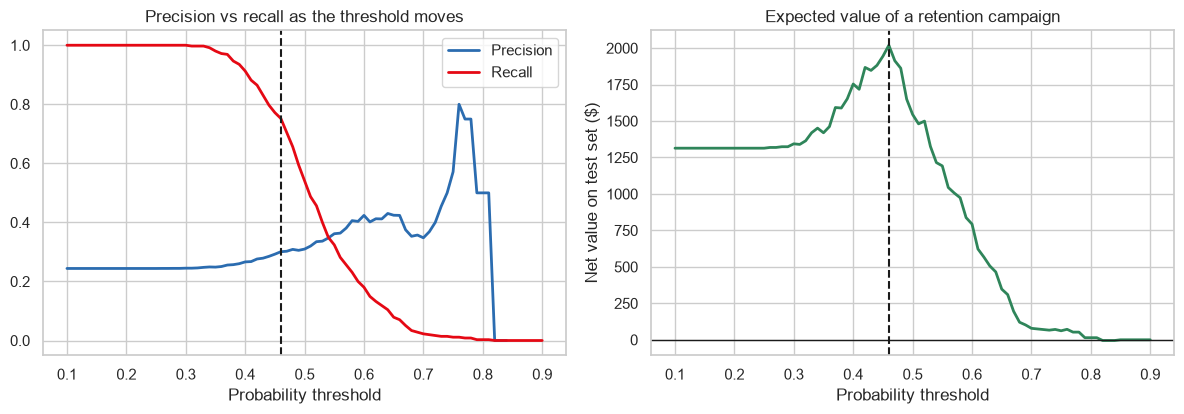

In [9]:
OFFER_COST = 5.0            # $ per customer contacted (discount / outreach cost)
SAVE_RATE = 0.30            # share of true would-be churners who stay because of the offer
MONTHS_SAVED = 6            # extra months of subscription a saved customer pays for
AVG_PRICE = float(df.monthly_price.mean())
VALUE_SAVED = AVG_PRICE * MONTHS_SAVED
print(f'avg monthly price ${AVG_PRICE:.2f} -> value of one saved customer ${VALUE_SAVED:.0f}; offer costs ${OFFER_COST:.0f}')

thr_grid = np.round(np.arange(0.10, 0.91, 0.01), 2); out = []
for t in thr_grid:
    flag = p_final >= t; tp = (flag & (y_test == 1)).sum(); n = flag.sum()
    out.append({'threshold': t, 'flagged': n, 'precision': tp / n if n else np.nan, 'recall': tp / (y_test == 1).sum(),
                'net_value': tp * SAVE_RATE * VALUE_SAVED - n * OFFER_COST})
thr = pd.DataFrame(out); best_row = thr.loc[thr.net_value.idxmax()]
OP_THR = float(best_row.threshold); no_model = (y_test == 1).sum() * SAVE_RATE * VALUE_SAVED - len(y_test) * OFFER_COST
print(f'Best threshold {OP_THR:.2f}: flags {int(best_row.flagged)} of {len(y_test)} test customers, precision {best_row.precision:.1%}, recall {best_row.recall:.1%}, net value ${best_row.net_value:,.0f}')
print(f'For comparison on the same {len(y_test)} customers: contact nobody = $0, contact everybody = ${no_model:,.0f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(thr.threshold, thr.precision, color=BLUE, lw=2, label='Precision'); axes[0].plot(thr.threshold, thr.recall, color=RED, lw=2, label='Recall')
axes[0].axvline(OP_THR, color='k', ls='--'); axes[0].set_xlabel('Probability threshold'); axes[0].legend(); axes[0].set_title('Precision vs recall as the threshold moves')
axes[1].plot(thr.threshold, thr.net_value, color=GREEN, lw=2); axes[1].axhline(0, color='k', lw=1); axes[1].axvline(OP_THR, color='k', ls='--')
axes[1].set_xlabel('Probability threshold'); axes[1].set_ylabel('Net value on test set ($)'); axes[1].set_title('Expected value of a retention campaign')
plt.tight_layout(); plt.savefig(FIG / '35_churn_threshold_economics.png', dpi=130, bbox_inches='tight'); plt.show()

## 8 · Final model at the chosen operating threshold

,accuracy,precision,recall,f1,roc_auc,pr_auc
threshold 0.50,0.594,0.310,0.541,0.394,0.621,0.336
operating threshold 0.46,0.513,0.301,0.752,0.430,0.621,0.336


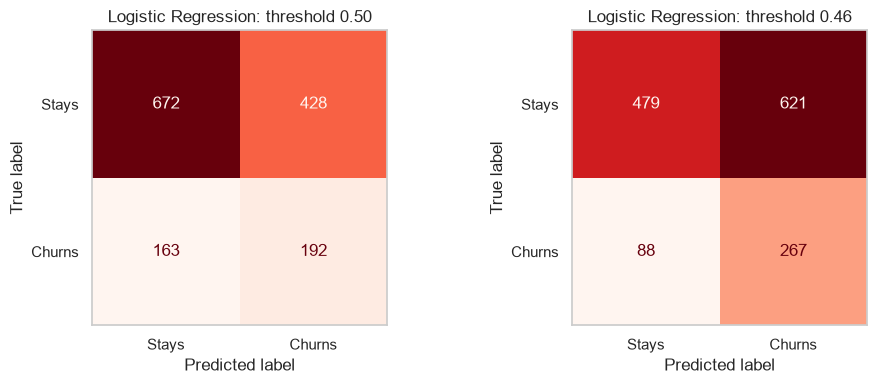

In [10]:
m05 = metrics_at(y_test, p_final, .5); mop = metrics_at(y_test, p_final, OP_THR)
cmp_ = pd.DataFrame({'threshold 0.50': m05, f'operating threshold {OP_THR:.2f}': mop}).T.round(3); display(cmp_)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [.5, OP_THR]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_final >= t).astype(int)), display_labels=['Stays', 'Churns']).plot(ax=ax, cmap='Reds', colorbar=False, values_format='d'); ax.set_title(f'{FINAL}: threshold {t:.2f}'); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / '36_churn_confusion_matrix.png', dpi=130, bbox_inches='tight'); plt.show()

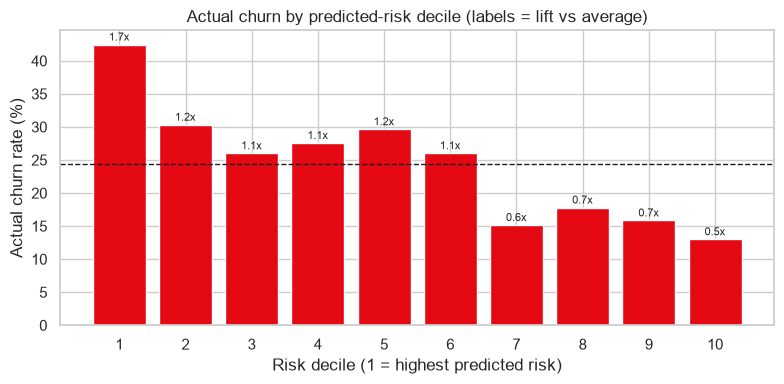

Top decile churns at 42.5% (1.74x average); top 3 deciles capture 40.6% of all churners.


In [11]:
# Lift by risk decile: how much better than random is the ranking?
d = pd.DataFrame({'p': p_final, 'y': y_test}); d['decile'] = pd.qcut(d.p.rank(method='first'), 10, labels=range(10, 0, -1)).astype(int)
lift = d.groupby('decile').agg(customers=('y', 'size'), churn_rate=('y', 'mean')).sort_index(); lift['lift'] = lift.churn_rate / y_test.mean()
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(lift.index.astype(str), lift.churn_rate * 100, color=RED); ax.axhline(y_test.mean() * 100, color='k', ls='--', lw=1)
for i, (r, l) in enumerate(zip(lift.churn_rate, lift.lift)): ax.text(i, r * 100 + .6, f'{l:.1f}x', ha='center', fontsize=8)
ax.set_xlabel('Risk decile (1 = highest predicted risk)'); ax.set_ylabel('Actual churn rate (%)'); ax.set_title('Actual churn by predicted-risk decile (labels = lift vs average)')
plt.tight_layout(); plt.savefig(FIG / '37_churn_lift_deciles.png', dpi=130, bbox_inches='tight'); plt.show()
print(f'Top decile churns at {lift.churn_rate.iloc[0]:.1%} ({lift.lift.iloc[0]:.2f}x average); top 3 deciles capture {(lift.churn_rate.iloc[:3] * lift.customers.iloc[:3]).sum() / (lift.churn_rate * lift.customers).sum():.1%} of all churners.')

## 9 · What drives the model? (permutation importance on the test set, drop in ROC-AUC)

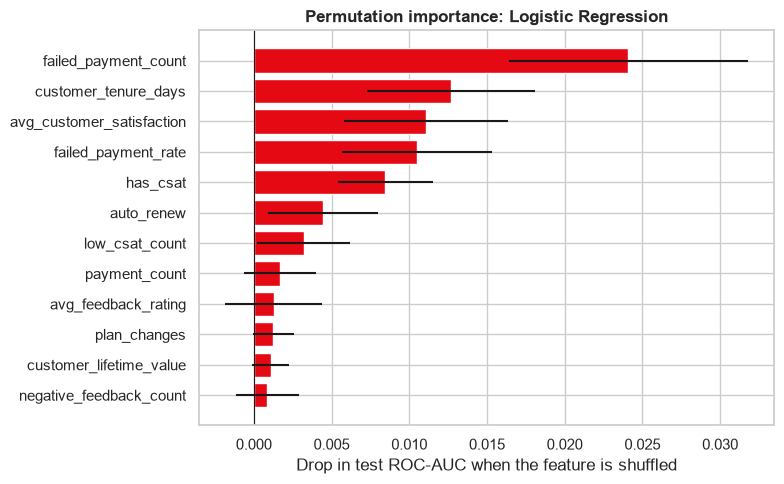

Top drivers: failed_payment_count, customer_tenure_days, avg_customer_satisfaction, failed_payment_rate, has_csat, auto_renew


In [12]:
pi = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False); err = pd.Series(pi.importances_std, index=X_test.columns).reindex(imp.index)
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(top.index, top.values, xerr=err.reindex(top.index).values, color=RED); ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('Drop in test ROC-AUC when the feature is shuffled'); ax.set_title(f'Permutation importance: {FINAL}', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / '38_churn_feature_importance.png', dpi=130, bbox_inches='tight'); plt.show()
print('Top drivers:', ', '.join(imp.head(6).index))

## 10 · Model-choice justification

**Final model: regularised Logistic Regression** (`class_weight='balanced'`, C = 0.003).

**1. The models are statistically tied, so the simplest one wins.** Tuned 5-fold CV ROC-AUC: Logistic Regression 0.600, Random Forest 0.595, XGBoost 0.593, Gradient Boosting 0.588. The whole spread is about one AUC point, and Random Forest sits inside one standard error (0.006) of the leader. On the held-out test set the order shuffles (LR 0.621, XGBoost 0.615, Gradient Boosting 0.606, Random Forest 0.601); with 1,455 test customers an AUC difference under ~0.015 is noise. When performance is a tie, the model you can explain and audit should win.

**2. Why complex models don't help here.** Before tuning, the tree models scored *worse* than logistic regression in CV (XGBoost 0.52, Gradient Boosting 0.54, Random Forest 0.56 vs LR 0.59), which is the signature of overfitting to noise. They only recovered after heavy regularisation (depth 2-3, large leaves, learning rate 0.02). The usable signal is weak and mostly monotonic (more failed payments, shorter tenure, lower satisfaction), exactly what a linear model captures. This matches the PRD's note that the churn relationship is intentionally noisy.

**3. What the model learned.** Top drivers by permutation importance: `failed_payment_count`, `customer_tenure_days`, `avg_customer_satisfaction`, `failed_payment_rate`, `has_csat`, `auto_renew`. These agree with the EDA, and they are easy to turn into plain-language explanations for the copilot.

**4. Accuracy is the wrong headline metric.** Predicting "nobody churns" is 75.6% accurate. The model's accuracy at threshold 0.50 is 59.4% *because* class weighting deliberately trades accuracy for recall: at 0.50 it finds 54% of churners (recall 0.54) with 31% precision (F1 0.39, ROC-AUC 0.62, PR-AUC 0.34 against a 0.24 baseline). Judge it by lift: the top-risk decile churns at 42.5% (1.74x the average), and the top three deciles contain 40.6% of all churners.

**5. Precision vs recall in a retention-offer context.** The right trade-off depends on money, not on a default 0.50 cut-off. With the illustrative assumptions in section 7 (offer costs $5, 30% of would-be churners accept, a saved customer is worth about $81), an offer pays for itself whenever precision is above 5 / (0.30 x 80.64) = **20.7%**. The base churn rate is already 24%, so contacting *everyone* is profitable on test data ($1,314). The model's job is to do better than that: at the net-value-optimal threshold of 0.46 it flags 61% of customers at 30% precision and 75% recall for **$2,020 net (+54% vs contacting everyone)**. If offers are expensive or budget-capped, raise the threshold and work down the risk deciles instead; if a lost customer is very valuable, lower it and accept more false alarms. A false negative (missed churner) costs ~$81 of future revenue, a false positive costs $5, so this use case should favour recall.

**6. Limitations (stated honestly).**
* ROC-AUC 0.62 is modest. A leaky build (features measured up to the exit date) reached 0.71 in notebook 03, but that number is not achievable in production, so I do not report it as the model's performance.
* One snapshot (2025-09-30) and one random split. Scoring today's customers uses a 90-day window shifted to Apr-Jun 2026, so some distribution drift is possible.
* The economic assumptions (cost, acceptance rate, months saved) are illustrative inputs, not facts; the threshold moves with them.

## 11 · Save the model, metrics and today's churn scores

In [13]:
# refit-free: final_model is already fitted on the training set. Risk tiers are fixed probability cut-offs from the TEST score distribution.
q80, q50 = np.quantile(p_final, [.80, .50])
bundle = {'model': final_model, 'name': FINAL, 'features': NUM + CAT, 'numeric': NUM, 'categorical': CAT,
          'operating_threshold': OP_THR, 'tier_cutoffs': {'high': float(max(q80, OP_THR)), 'medium': float(q50)},
          'trained_on': 'snapshot 2025-09-30 (outcome window: 9 months)', 'assumptions': dict(offer_cost=OFFER_COST, save_rate=SAVE_RATE, months_saved=MONTHS_SAVED, avg_price=AVG_PRICE)}
joblib.dump(bundle, MODELS / 'churn_model.joblib')

summary = {'final_model': FINAL, 'selection_rule': 'highest tuned CV ROC-AUC; prefer simpler model within 1 SE',
           'cv_auc': {k: float(v) for k, v in cv_auc.items()}, 'test_threshold_0.5': m05, 'test_operating_threshold': {'threshold': OP_THR, **mop},
           'test_all_models': res.to_dict('index'), 'leakage_note': 'features measured as of 2025-09-30; outcome = churn after that date',
           'top_features': list(imp.head(10).index)}
json.dump(summary, open(REP / 'churn_model_metrics.json', 'w'), indent=2, default=float)

# Score every currently active customer using features measured up to 2026-06-30
cur = pd.read_csv(PROC / 'customer_features.csv'); act = cur[cur.churned == 0].copy()
act['churn_risk_score'] = final_model.predict_proba(act[NUM + CAT])[:, 1]
act['risk_tier'] = np.where(act.churn_risk_score >= bundle['tier_cutoffs']['high'], 'High', np.where(act.churn_risk_score >= bundle['tier_cutoffs']['medium'], 'Medium', 'Low'))
act[['customer_id', 'churn_risk_score', 'risk_tier']].round({'churn_risk_score': 4}).to_csv(PROC / 'churn_scores.csv', index=False)
print(act.risk_tier.value_counts().to_dict(), '| scored', len(act), 'active customers')
print('saved: models/churn_model.joblib, reports/churn_model_metrics.json, data/processed/churn_scores.csv')

{'Low': 3402, 'Medium': 1458, 'High': 1149} | scored 6009 active customers
saved: models/churn_model.joblib, reports/churn_model_metrics.json, data/processed/churn_scores.csv
